### **Supervised Learning**

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

### K-Nearest Neighbors (KNN)

#### 1. ტრენინგის ფაზა:
- ფაქტობრივად არ ხდება ტრენინგი!
- მოდელი უბრალოდ იმახსოვრებს მთელ სატრენინგო მონაცემს.
- ამიტომ მას ხშირად ეძახიან „lazy learner“-ს, განსხვავებით „eager learner“-ებისგან (მაგ. Decision Tree).

---

#### 2. პროგნოზის ფაზა:
როცა მოდელს ახალი მაგალითი მიეწოდება:

KNN პროგნოზირებს ახალი მონაცემის კლასს ან მნიშვნელობას, ყველაზე ახლოს მყოფი `k` მონაცემის საშუალებით.

1. არჩიეთ `k` (მონაცემთა რაოდენობა, რომელზეც დაყრდნობა მოხდება).  
2. გამოითვალეთ მანძილი ახალი მონაცემის და არსებული მონაცემების შორის (მაგალითად, ევკლიდეს მანძილი):
   
   $d = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$
   
3. იპოვეთ `k` უახლოესი მეზობელი და გამოითვალეთ შედეგი:
   - კლასიფიკაციისთვის → უმრავლესობის კენჭისყრა (Majority Voting).
   - რეგრესიისთვის → საშუალო მნიშვნელობის აღება (Averaging).

- KNN არის არაპარამეტრიული → არ მოითხოვს მონაცემთა განაწილებაზე წინასწარ ვარაუდებს.  
- დიდ მონაცემებზე ნელია → რადგან ითვლის მანძილებს ყველა წერტილთან.
- კარგად მუშაობს პატარა და საშუალო ზომის მონაცემებზე.  

---

#### როგორ ავარჩიოთ სწორი `k`?
- მცირე `k` (მაგ. `k=1`) → მოდელი ზედმეტად მგრძნობიარეა (Overfitting).  
- დიდი `k` (მაგ. `k=50`) → მონაცემების განზოგადება ხდება ზედმეტად (Underfitting).  
- საუკეთესო პრაქტიკა → გამოიყენეთ `cross-validation` `k`-ის ოპტიმიზაციისთვის.  

<img src="../../images/knn.png" alt="knn" width=600>

პარამეტრი | ახსნა
-------|-------
n_neighbors | k-ს მნიშვნელობა - ანუ რამდენი უახლოესი მეზობელი იქნება გათვალისწინებული
metric | მანძილის გაზომვის მეთოდი (minkowski, euclidean, manhattan)

#### **Penguins Dataset**: პინგვინის სახეობის დადგენა მათი ნისკარტის სიგრძის, ფარფლის სიგრძისა და სხეულის მასის მიხედვით.

In [3]:
# Load Dataset
df_penguins = sns.load_dataset("penguins")
df_penguins = df_penguins.dropna()
df_penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


In [4]:
#  მახასიათებლების და სამიზნე სვეტის შერჩევა (features & target)
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
target = "species"

X = df_penguins[features]
y = df_penguins[target]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
# Train KNN Classifier
knn = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'euclidean'
,metric_params,None
,n_jobs,None


In [6]:
# პროგნოზი
y_pred = knn.predict(X_test)

In [7]:
# მოდელის ევალუაცია, კლასიფიკაციის რეპორტი
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.82

Classification Report:
               precision    recall  f1-score   support

      Adelie       0.83      0.81      0.82        31
   Chinstrap       0.73      0.62      0.67        13
      Gentoo       0.85      0.96      0.90        23

    accuracy                           0.82        67
   macro avg       0.80      0.79      0.79        67
weighted avg       0.82      0.82      0.82        67



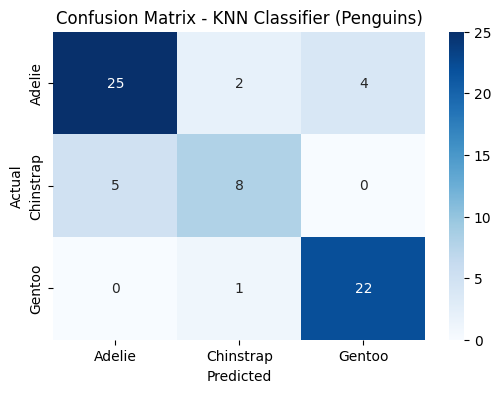

In [8]:
# Confusion Matrix 
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=knn.classes_, yticklabels=knn.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - KNN Classifier (Penguins)")
plt.show()

In [9]:
# Feature Importance 
result = permutation_importance(knn, X_test, y_test, n_repeats=30, random_state=42, scoring="accuracy")

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance Mean": result.importances_mean,
}).sort_values(by="Importance Mean", ascending=False)

importance_df

,Feature,Importance Mean
3,body_mass_g,0.387562
0,bill_length_mm,0.091045
2,flipper_length_mm,0.083085
1,bill_depth_mm,0.000000


როგორც ვხედავთ, როდესაც მოდელი მახასიათებლების სკალირების გარეშე გავწვრთენით, იმ მახასიათებლებს, რომლებიც უფრო დიდი მნიშვნელობებით გამოირჩევიან (მაგალითად, body_mass_g) ექნებათ მეტი გავლენა. ეს ხდება, რადგანაც  არის დისტანციის გამოთვლაზე დაფუძნებული მეთოდი.

გამოვიყენოთ Feature Scaling (მახასიათებლების სკალირება/სტანდარტიზაცია) როგორც preprocessing step.

In [10]:
# მონაცემების სკალირება
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
# Train KNN Classifier
knn = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'euclidean'
,metric_params,None
,n_jobs,None


In [12]:
# პროგნოზი
y_pred = knn.predict(X_test)

In [13]:
# მოდელის ევალუაცია, კლასიფიკაციის რეპორტი
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 1.00

Classification Report:
               precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        31
   Chinstrap       1.00      1.00      1.00        13
      Gentoo       1.00      1.00      1.00        23

    accuracy                           1.00        67
   macro avg       1.00      1.00      1.00        67
weighted avg       1.00      1.00      1.00        67



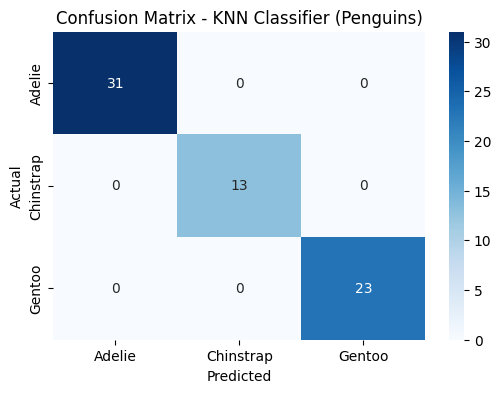

In [14]:
# Confusion Matrix 
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=knn.classes_, yticklabels=knn.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - KNN Classifier (Penguins)")
plt.show()

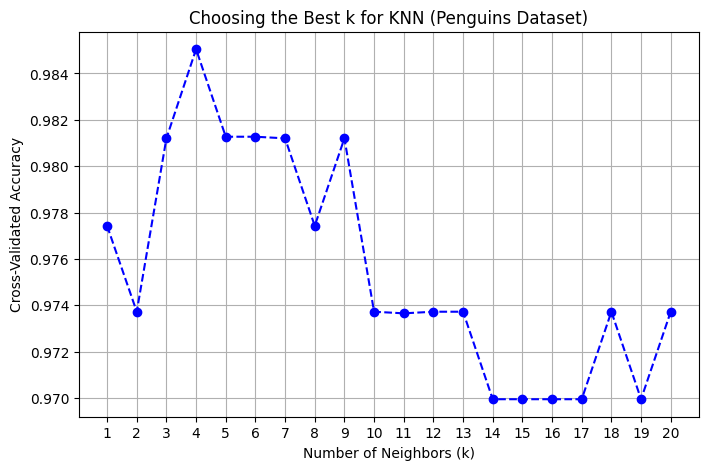

In [15]:
# მოვძებნოთ საუკეთესო k
k_range = range(1, 21)  # k მნიშვნელობები 1-დან 20-მდე
accuracies = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring="accuracy")
    accuracies.append(scores.mean())

# Plot Accuracy vs. `k`
plt.figure(figsize=(8, 5))
plt.plot(k_range, accuracies, marker="o", linestyle="dashed", color="blue")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Cross-Validated Accuracy")
plt.title("Choosing the Best k for KNN (Penguins Dataset)")
plt.xticks(range(1, 21))
plt.grid(True)
plt.show()

In [16]:
# ავარჩიოთ საუკეთესო k, მაქსიმალური accuracy-ის მიხედვით
best_k = k_range[np.argmax(accuracies)]
print(f"Best k = {best_k}, with Accuracy: {max(accuracies):.2f}")

Best k = 4, with Accuracy: 0.99


In [17]:
# გავწვრთნათ მოდელი არჩეული -ს მნიშვნელობით
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train, y_train)

,n_neighbors,4
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [18]:
# პროგნოზი
y_pred = knn_best.predict(X_test)

Test Accuracy with k=4: 1.00


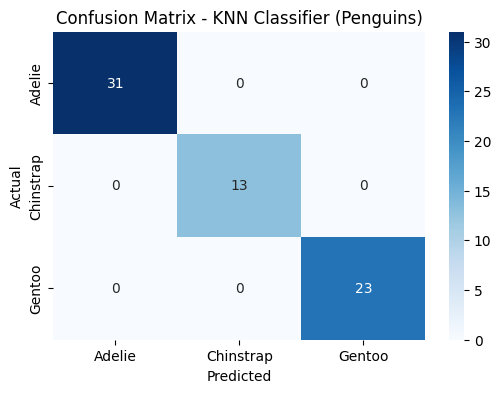

In [19]:
# მოდელის ევალუაცია
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy with k={best_k}: {accuracy:.2f}")

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=knn_best.classes_, yticklabels=knn_best.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - KNN Classifier (Penguins)")
plt.show()

In [20]:
# Feature Importance 
result = permutation_importance(knn_best, X_test, y_test, n_repeats=30, random_state=42, scoring="accuracy")

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance Mean": result.importances_mean,
}).sort_values(by="Importance Mean", ascending=False)

importance_df

,Feature,Importance Mean
0,bill_length_mm,0.324378
1,bill_depth_mm,0.148756
3,body_mass_g,0.046766
2,flipper_length_mm,0.035821


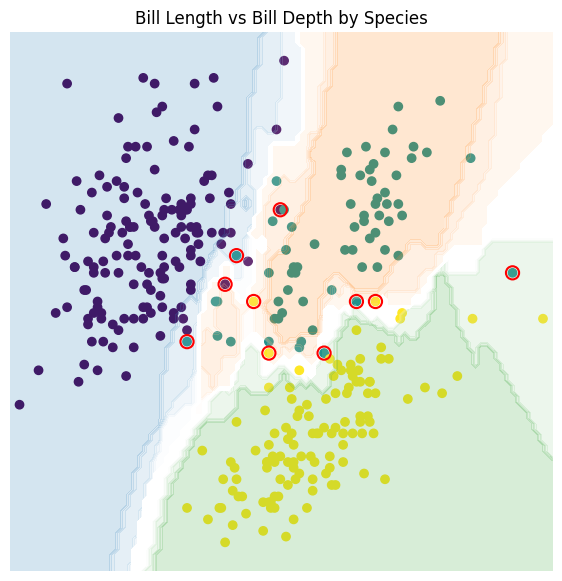

In [21]:
# Decision boundary: როგორ გამოყოფს მოდელი მონაცემებს ერთმანეთისგან
cm = plt.cm.RdBu
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = KNeighborsClassifier(n_neighbors=5)
clf.fit(X_train[["bill_length_mm", "bill_depth_mm"]], y_train)

X_2d = X[["bill_length_mm", "bill_depth_mm"]]
y_pred = clf.predict(X_2d)
misclassified = y_pred != y

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X["bill_length_mm"], X["bill_depth_mm"], c=y.astype("category").cat.codes)
DecisionBoundaryDisplay.from_estimator(clf, X[["bill_length_mm", "bill_depth_mm"]], cmap=cm, alpha=0.2, ax=ax, eps=0.5)
ax.scatter(X.loc[misclassified, "bill_length_mm"], X.loc[misclassified, "bill_depth_mm"], facecolors="none", edgecolors="red", s=90, linewidths=1.5,)
plt.title("Bill Length vs Bill Depth by Species")
plt.axis("off")
plt.show()

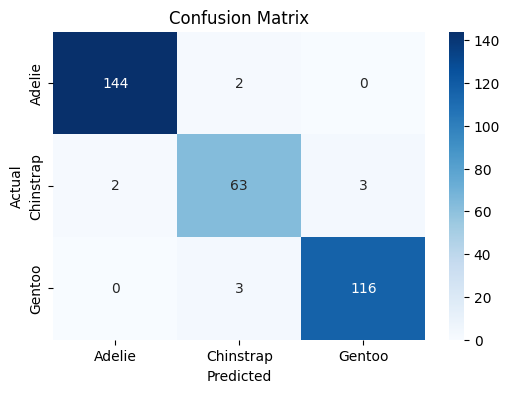

In [22]:
# მოდელის ევალუაცია
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y, clf.predict(X[["bill_length_mm", "bill_depth_mm"]])), annot=True, fmt="d", cmap="Blues",
            xticklabels=knn_best.classes_, yticklabels=knn_best.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### KNeighborsRegressor

In [23]:
# სინთეტიკური მონაცემების დაგენერირება
X, y = make_regression(n_samples=100, n_features=1, noise=15, random_state=42)

In [24]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [25]:
# მონაცემების სკალირება
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [26]:
# Train KNN Classifier
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [27]:
# პროგნოზი
y_pred = knn.predict(X_test)

x0: -0.98
Neighbor X: [-0.98 -1.03 -1.08 -0.86 -0.79]
Neighbor y: [-35.11 -30.3  -43.56 -46.52 -15.54]
Mean of neighbor y: -34.21
KNN prediction at x0: -34.21


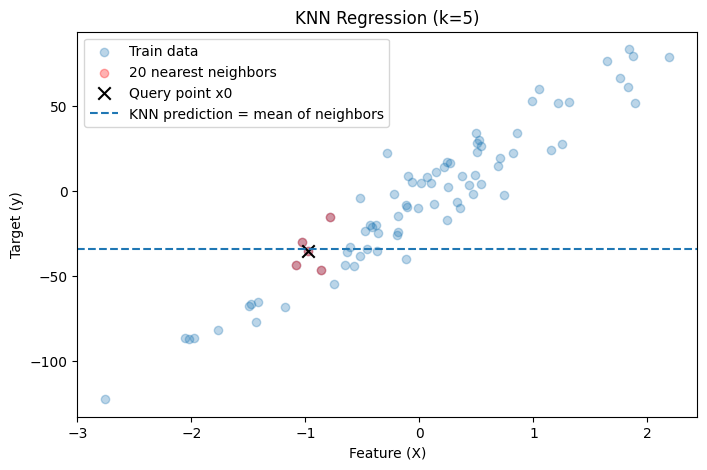

In [28]:
# Choose one query point
x0 = X_train[1]           # shape (1,)
y0_true = y_train[1]

# In 1D, neighbors are just the k points with smallest |x - x0|
distances = np.abs(X_train.flatten() - x0[0])
neighbor_idx = np.argsort(distances)[:5]

X_neighbors = X_train[neighbor_idx]
y_neighbors = y_train[neighbor_idx]

# KNN prediction for x0 (should be mean of neighbor targets)
y0_pred = knn.predict(x0.reshape(1, -1))[0]
y_neighbors_mean = y_neighbors.mean()

print("x0:", round(x0[0], 2))
print("Neighbor X:", X_neighbors.flatten().round(2))
print("Neighbor y:", y_neighbors.round(2))
print("Mean of neighbor y:", y_neighbors_mean.round(2))
print("KNN prediction at x0:", y0_pred.round(2))

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.3, label="Train data")
plt.scatter(X_neighbors, y_neighbors, color="red",  alpha=0.3,label=f"{k} nearest neighbors")
plt.scatter([x0], [y0_true], color="black", marker="x", s=80, label="Query point x0")
plt.axhline(y=y0_pred, linestyle="--", label="KNN prediction = mean of neighbors")
plt.xlabel("Feature (X)")
plt.ylabel("Target (y)")
plt.title(f"KNN Regression (k=5)")
plt.legend()
plt.show()

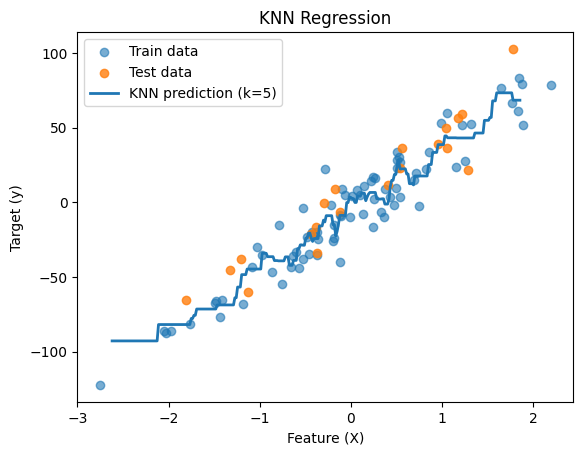

In [29]:
x_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_pred_grid = knn.predict(x_grid)

# data points + KNN curve
plt.scatter(X_train, y_train, alpha=0.6, label="Train data")
plt.scatter(X_test, y_test, alpha=0.8, label="Test data")
plt.plot(x_grid, y_pred_grid, linewidth=2, label="KNN prediction (k=5)")

plt.xlabel("Feature (X)")
plt.ylabel("Target (y)")
plt.legend()
plt.title("KNN Regression")
plt.show()

#### **Airbnb dataset:** ბინის გასაქირავებელი ფასის დადგენა ისეთი მახასიათებლების გამოყენებით როგორიცაა ოთახის ტიპი, საძინებლების რაოდენობა და მდებარეობა.

In [30]:
# Load Dataset
df_airbnb = pd.read_csv("../../datasets/airbnb/Airbnb_Open_Data.csv")
columns = ["room type", "neighbourhood group", "instant_bookable", "cancellation_policy", "service fee",
           "minimum nights", "number of reviews", "reviews per month", "availability 365", "price"]
# Data Cleaning: გავწმინდოთ ცარიელი მონაცემებისაგან
df_airbnb = df_airbnb[columns].rename(columns={c: c.replace(" ", "_") for c in columns})
df_airbnb = df_airbnb.dropna()
df_airbnb = df_airbnb.query("availability_365 < 366 and minimum_nights < 366").reset_index(drop=True)
df_airbnb.head()

,room_type,neighbourhood_group,instant_bookable,cancellation_policy,service_fee,minimum_nights,number_of_reviews,reviews_per_month,availability_365,price
0,Private room,Brooklyn,False,strict,$193,10.0,9.0,0.21,286.0,$966
1,Entire home/apt,Manhattan,False,moderate,$28,30.0,45.0,0.38,228.0,$142
2,Entire home/apt,Brooklyn,True,moderate,$74,30.0,270.0,4.64,322.0,$368
3,Entire home/apt,Manhattan,False,moderate,$41,10.0,9.0,0.10,289.0,$204
4,Private room,Brooklyn,False,moderate,$14,45.0,49.0,0.40,224.0,$71


In [31]:
# მონაცემების დამუშავება
# მოვაშოროთ '$' ნიშანი და გარდავქმნათ სვეტი float ტიპად 
df_airbnb["service_fee"] = df_airbnb["service_fee"].str.replace("$", "").str.replace(",", "").astype(float)
df_airbnb["price"] = df_airbnb["price"].str.replace("$", "").str.replace(",", "").astype(float)

In [32]:
# OneHotEncoder
df_airbnb = pd.get_dummies(df_airbnb) 

In [33]:
#  Select features & target
features = df_airbnb.drop(columns=["price"]).columns
target = "price"

X = df_airbnb[features]
y = df_airbnb[target]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [34]:
# მონაცემების სკალირება
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [35]:
# Train KNN Regressor
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [36]:
# პროგნოზი
y_pred = knn.predict(X_test)

In [37]:
# მოდელის ევალუაცია
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # ერთეული - $
print(f"Mean Squared Error (MSE): {mse:.2f}") # ერთეული - $²
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # ერთეული - $
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 31.20
Mean Squared Error (MSE): 2675.51
Root Mean Squared Error (RMSE): 51.73
R² Score: 0.98


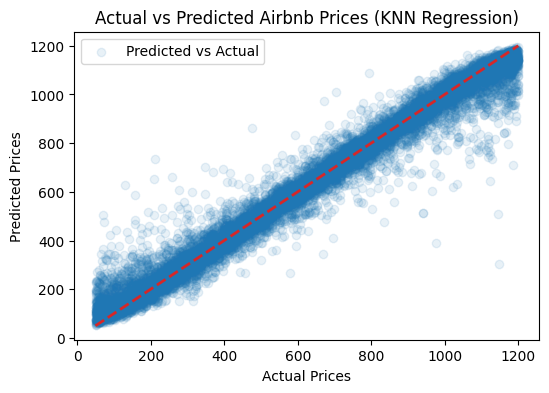

In [38]:
# Actual vs Predicted
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred, alpha=0.1, label="Predicted vs Actual")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color="C3", linestyle="dashed", linewidth=2)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Airbnb Prices (KNN Regression)")
plt.legend()
plt.show()

In [ ]:
# Feature Importance
result = permutation_importance(knn, X_test, y_test, n_repeats=5, random_state=42)

importances = pd.DataFrame({
    "Feature": features,
    "Importance": result.importances_mean
}).sort_values("importance", ascending=False)

importances